# Proyecto 2 Técnicas de Aprendizaje de Máquina: Siniestros Víales

## Importación de librerias

In [1]:
%pip install scikit-learn
%pip install kagglehub
%pip install pandas 
%pip install numpy 
%pip install matplotlib 
%pip install seaborn 
%pip install plotly


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


... (4 outputs left out)

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import sklearn 

c:\Users\carlo\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Lectura del Archivo

In [3]:
df = pd.read_csv("historico_siniestros_bogota_d.c_-.csv", encoding="utf-8")

## Análisis de dimensionalidad

In [4]:
df.head()  # Muestra las primeras filas del DataFrame

,X,Y,OBJECTID,FORMULARIO,CODIGO_ACCIDENTE,FECHA_OCURRENCIA_ACC,ANO_OCURRENCIA_ACC,DIRECCION,GRAVEDAD,CLASE_ACC,LOCALIDAD,FECHA_HORA_ACC,LATITUD,LONGITUD,CIV,PK_CALZADA
0,-74.090924,4.693807,1,A000640275,4484660,2017/06/12 00:00:00+00,2017,AV AVENIDA BOYACA-CL 79 02,SOLO DANOS,CHOQUE,ENGATIVA,2017/06/12 05:30:00+00,4.693807,-74.090924,10006772.0,221236.0
1,-74.121000,4.603000,2,A001233353,10533499,2020/11/19 00:00:00+00,2020,CL 26 S- KR 50 02,CON HERIDOS,OTRO,PUENTE ARANDA,2020/11/19 02:05:00+00,4.603000,-74.121000,16004560.0,NaN
2,-74.042000,4.682000,4,A001232786,10533629,2020/11/10 00:00:00+00,2020,KR 9 - CL 100 02,SOLO DANOS,CHOQUE,USAQUEN,2020/11/10 13:30:00+00,4.682000,-74.042000,30001107.0,NaN
3,-74.166937,4.587187,7,A000200705,4412699,2015/05/11 00:00:00+00,2015,CL 63A-KR 72 S 02,SOLO DANOS,CHOQUE,CIUDAD BOLIVAR,2015/05/11 10:50:00+00,4.587187,-74.166937,19001483.0,136166.0
4,-74.092901,4.607648,8,A000402862,4447845,2016/06/08 00:00:00+00,2016,KR 27-CL 9 14,SOLO DANOS,CHOQUE,LOS MARTIRES,2016/06/08 21:30:00+00,4.607648,-74.092901,14000548.0,239719.0


### Tipo de datos

In [5]:
print(df.info())  # Información general del DataFrame

<class 'pandas.DataFrame'>
RangeIndex: 199146 entries, 0 to 199145
Data columns (total 16 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   X                     199146 non-null  float64
 1   Y                     199146 non-null  float64
 2   OBJECTID              199146 non-null  int64  
 3   FORMULARIO            199146 non-null  str    
 4   CODIGO_ACCIDENTE      199146 non-null  int64  
 5   FECHA_OCURRENCIA_ACC  199146 non-null  str    
 6   ANO_OCURRENCIA_ACC    199146 non-null  int64  
 7   DIRECCION             199146 non-null  str    
 8   GRAVEDAD              199146 non-null  str    
 9   CLASE_ACC             199146 non-null  str    
 10  LOCALIDAD             199100 non-null  str    
 11  FECHA_HORA_ACC        199146 non-null  str    
 12  LATITUD               199146 non-null  float64
 13  LONGITUD              199146 non-null  float64
 14  CIV                   197445 non-null  float64
 15  PK_CALZADA 

In [6]:
# Nulos por columna
df.isnull().sum()

X                           0
Y                           0
OBJECTID                    0
FORMULARIO                  0
CODIGO_ACCIDENTE            0
FECHA_OCURRENCIA_ACC        0
ANO_OCURRENCIA_ACC          0
DIRECCION                   0
GRAVEDAD                    0
CLASE_ACC                   0
LOCALIDAD                  46
FECHA_HORA_ACC              0
LATITUD                     0
LONGITUD                    0
CIV                      1701
PK_CALZADA              37974
dtype: int64

In [7]:
# =========================================================
# 1. DIMENSIONALIDAD Y CARDINALIDAD
# =========================================================
card = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "valores_unicos": df.nunique(),
    "pct_unicos": (df.nunique() / len(df) * 100).round(2)
}).sort_values("valores_unicos", ascending=False)
print(card)

# Columnas con un valor distinto por fila = identificadores
ids = card[card["pct_unicos"] > 99].index.tolist()
print("\nPosibles identificadores:", ids)

# ¿X/Y son lo mismo que LONGITUD/LATITUD?
print("\nDiferencia máx X vs LONGITUD:", (df["X"] - df["LONGITUD"]).abs().max())
print("Diferencia máx Y vs LATITUD:", (df["Y"] - df["LATITUD"]).abs().max())

                         tipo  valores_unicos  pct_unicos
FORMULARIO                str          199146      100.00
OBJECTID                int64          199146      100.00
CODIGO_ACCIDENTE        int64          199146      100.00
FECHA_HORA_ACC            str          162457       81.58
Y                     float64          110417       55.45
X                     float64          109453       54.96
LATITUD               float64          108427       54.45
LONGITUD              float64          107698       54.08
DIRECCION                 str          100085       50.26
CIV                   float64           38419       19.29
PK_CALZADA            float64           37953       19.06
FECHA_OCURRENCIA_ACC      str            2445        1.23
LOCALIDAD                 str              20        0.01
ANO_OCURRENCIA_ACC      int64               7        0.00
CLASE_ACC                 str               7        0.00
GRAVEDAD                  str               3        0.00

Posibles iden

In [8]:
# Posibles filas duplicadas
print("Filas duplicadas:", df.duplicated().sum())

Filas duplicadas: 0


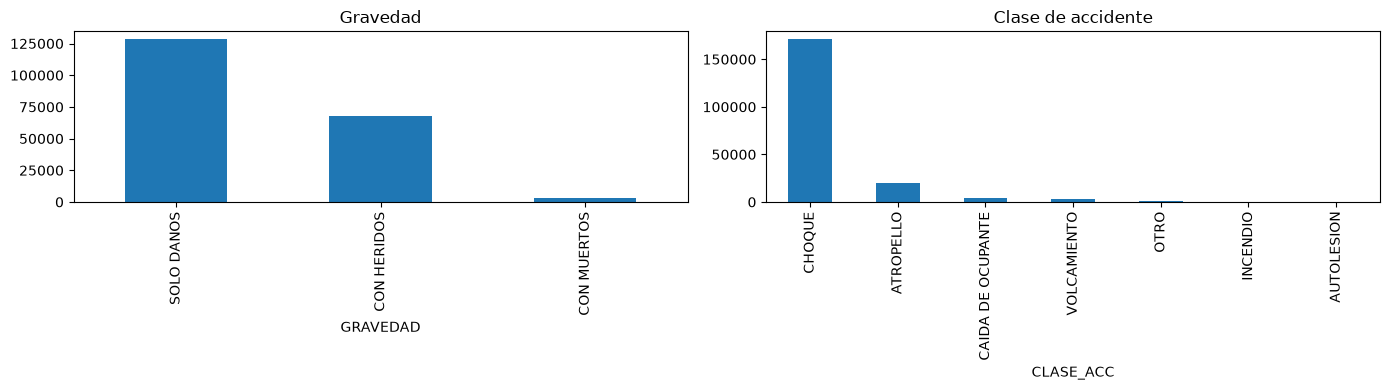

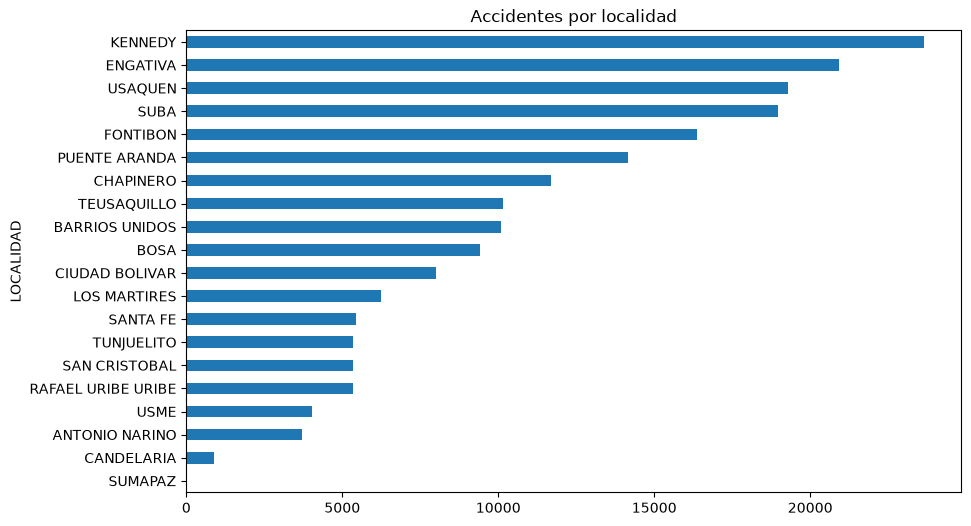

GRAVEDAD,CON HERIDOS,CON MUERTOS,SOLO DANOS
LOCALIDAD,,,
ANTONIO NARINO,43.9,2.2,53.9
BARRIOS UNIDOS,27.4,1.0,71.6
BOSA,46.8,2.1,51.1
CANDELARIA,33.7,1.7,64.6
CHAPINERO,23.1,0.8,76.1
CIUDAD BOLIVAR,46.2,3.1,50.7
ENGATIVA,30.9,1.4,67.7
FONTIBON,25.3,1.4,73.3
KENNEDY,40.6,1.9,57.5


In [9]:
# =========================================================
# 3. VARIABLES CATEGÓRICAS (BASE COMPLETA)
# =========================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df["GRAVEDAD"].value_counts().plot(kind="bar", ax=axes[0], title="Gravedad")
df["CLASE_ACC"].value_counts().plot(kind="bar", ax=axes[1], title="Clase de accidente")
plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 6))
df["LOCALIDAD"].value_counts().plot(kind="barh", title="Accidentes por localidad")
plt.gca().invert_yaxis(); plt.show()

# Proporción de gravedad dentro de cada localidad
pd.crosstab(df["LOCALIDAD"], df["GRAVEDAD"], normalize="index").round(3) * 100

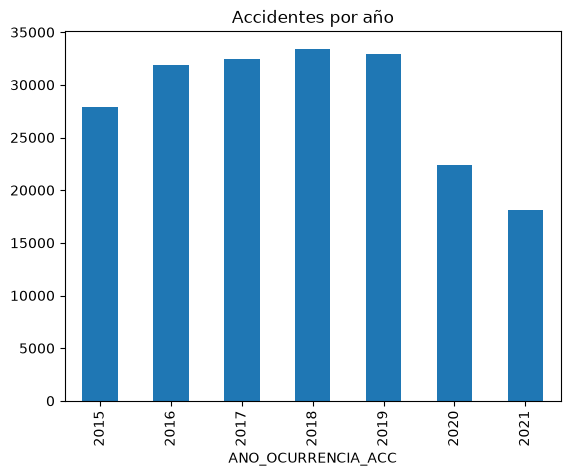

In [10]:
# =========================================================
# 4. VARIABLES TEMPORALES DERIVADAS
# =========================================================
df["FECHA_HORA"] = pd.to_datetime(df["FECHA_HORA_ACC"].str[:19], format="%Y/%m/%d %H:%M:%S")
df["HORA"] = df["FECHA_HORA"].dt.hour
df["DIA_SEMANA"] = df["FECHA_HORA"].dt.dayofweek          # 0 = lunes
df["MES"] = df["FECHA_HORA"].dt.month
df["FIN_SEMANA"] = df["DIA_SEMANA"].isin([5, 6]).astype(int)

def franja(h):
    if h < 6:   return "Madrugada"
    if h < 12:  return "Mañana"
    if h < 18:  return "Tarde"
    return "Noche"
df["FRANJA"] = df["HORA"].apply(franja)

# Accidentes por año (ojo con 2020-2021 por la pandemia)
df["ANO_OCURRENCIA_ACC"].value_counts().sort_index().plot(kind="bar", title="Accidentes por año")
plt.show()

Accidentes con muertos: 3239 (1.63% del total)


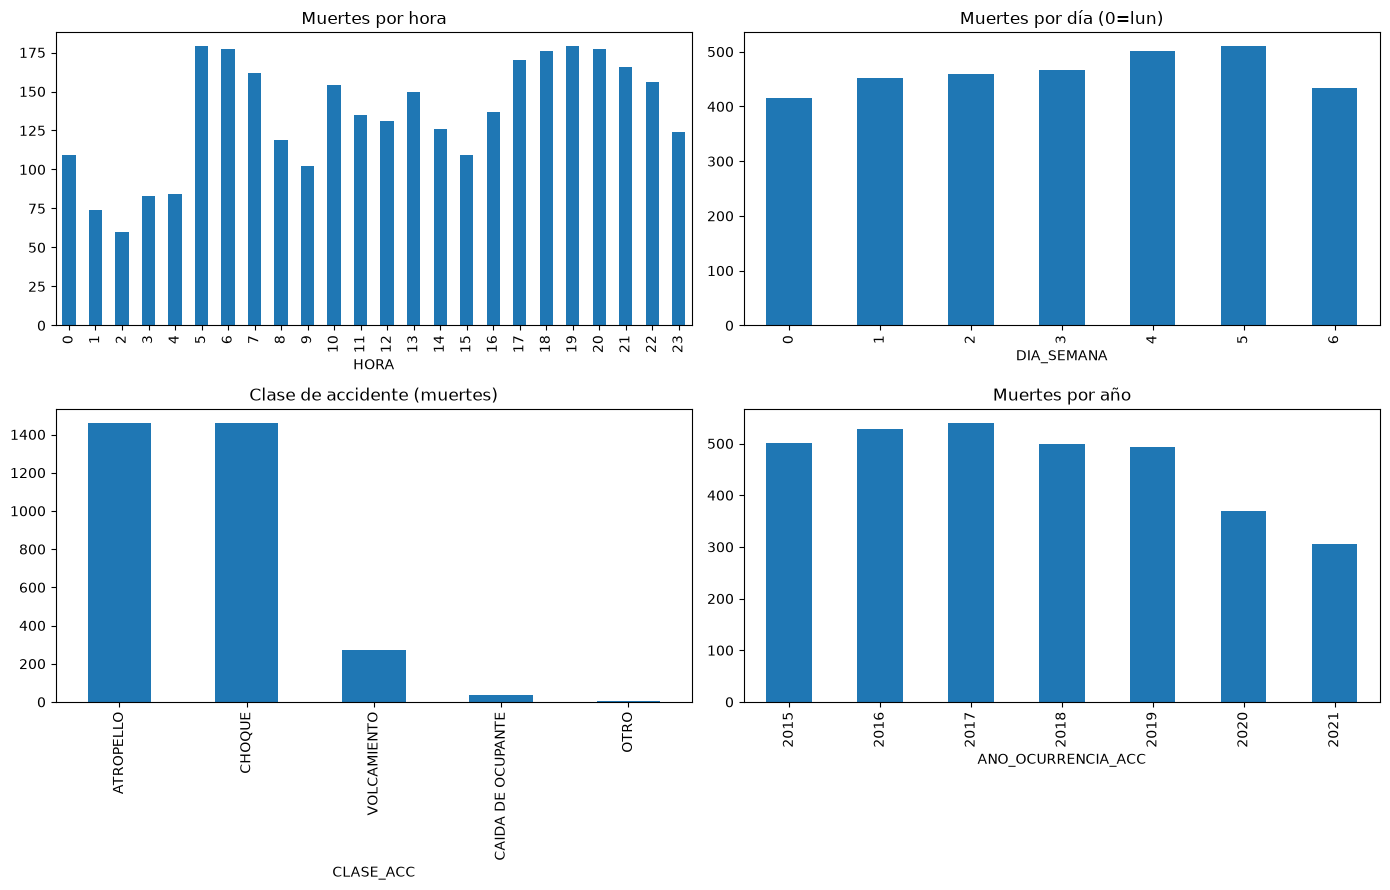

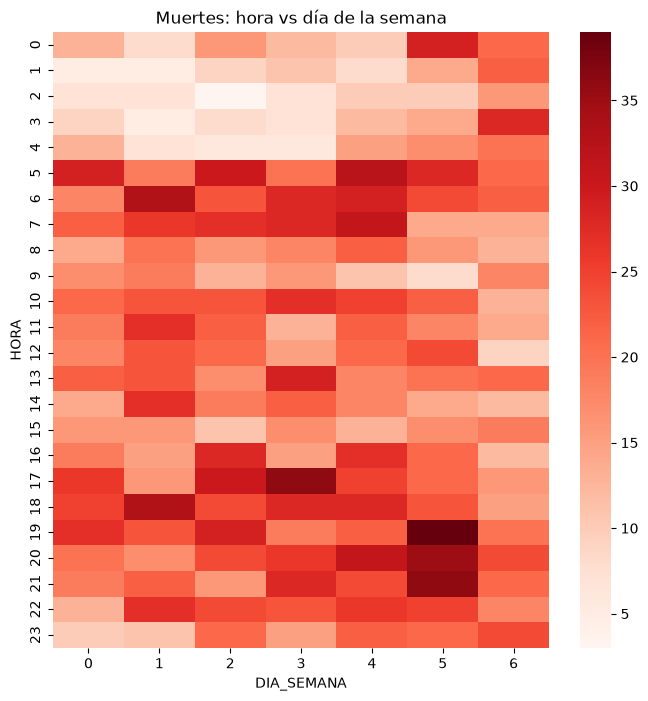

In [11]:
# =========================================================
# 5. FILTRO: ACCIDENTES CON MUERTOS (foco del proyecto)
# =========================================================
dm = df[df["GRAVEDAD"] == "CON MUERTOS"].copy()
print("Accidentes con muertos:", len(dm), f"({len(dm)/len(df)*100:.2f}% del total)")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
dm["HORA"].value_counts().sort_index().plot(kind="bar", ax=axes[0, 0], title="Muertes por hora")
dm["DIA_SEMANA"].value_counts().sort_index().plot(kind="bar", ax=axes[0, 1],
    title="Muertes por día (0=lun)")
dm["CLASE_ACC"].value_counts().plot(kind="bar", ax=axes[1, 0], title="Clase de accidente (muertes)")
dm["ANO_OCURRENCIA_ACC"].value_counts().sort_index().plot(kind="bar", ax=axes[1, 1],
    title="Muertes por año")
plt.tight_layout(); plt.show()

# Mapa de calor hora x día
pivot = dm.pivot_table(index="HORA", columns="DIA_SEMANA", values="CODIGO_ACCIDENTE", aggfunc="count")
plt.figure(figsize=(8, 8))
sns.heatmap(pivot, cmap="Reds")
plt.title("Muertes: hora vs día de la semana"); plt.show()

Registros con coordenadas sospechosas: 0


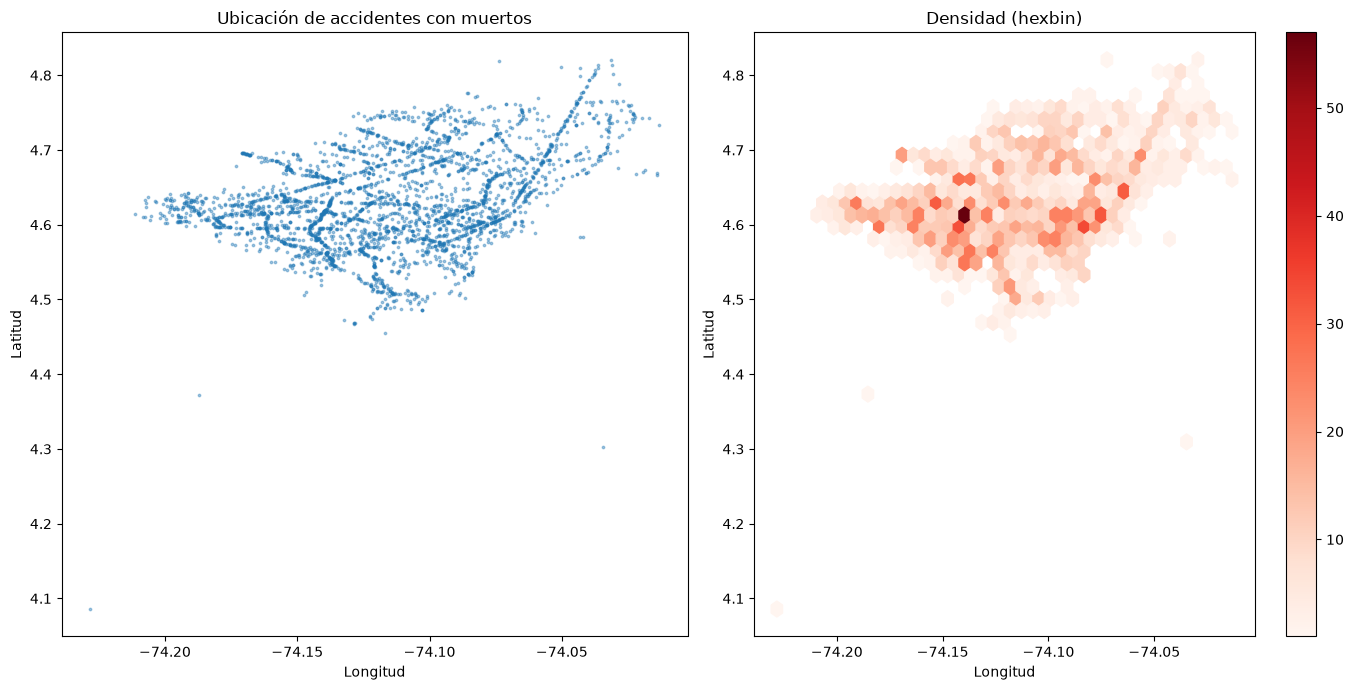

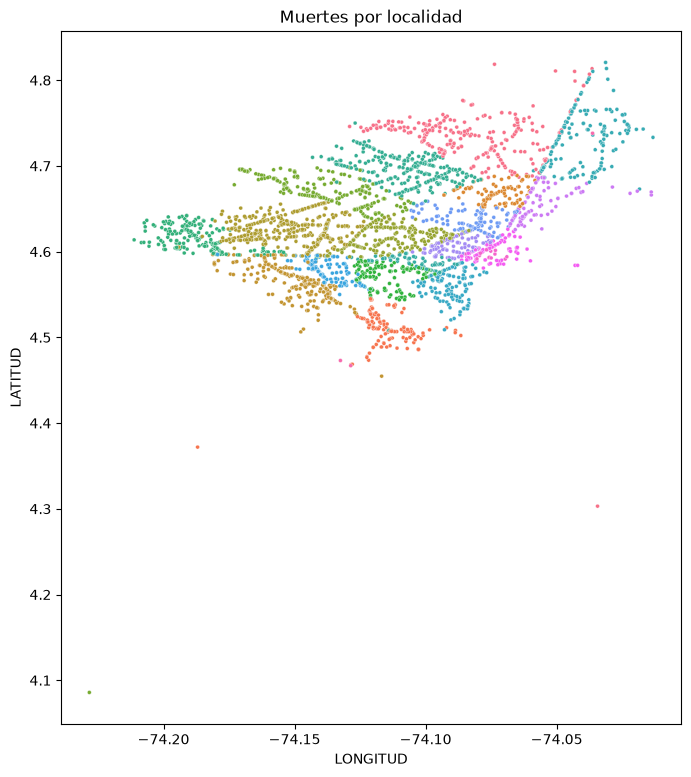

DIRECCION
AV AVENIDA BOYACA-AV AVENIDA PRIMERO DE MAYO 02    5
AV AVENIDA BOYACA-CL 44 S 02                       4
AV AVENIDA DE LAS AMERICAS-KR 68 02                4
AV AVENIDA BOYACA-CL 72 02                         3
CL 80-KR 72 2                                      3
AV AVENIDA CIUDAD DE CALI-CL 15A 91                3
KR 106-CL 15A 25                                   3
AK 68-CL 13 02                                     3
AC 80-KR 112 02                                    3
KR 80-CL 2 51                                      3
CL 6 - KR 47 02                                    2
AV AVENIDA DE LAS AMERICAS-KR 74 02                2
CL 61 S- KR 23 02                                  2
AV AVENIDA CIUDAD DE CALI-CL 11B 51                2
AV AVENIDA BOYACA-CL 72 2                          2
Name: count, dtype: int64
CIV
0.0           17
50008335.0     9
10003679.0     8
8005344.0      7
50008334.0     7
11012293.0     7
10000256.0     6
9003474.0      6
8000071.0      6
8008510.0   

In [12]:
# =========================================================
# 6. ANÁLISIS ESPACIAL
# =========================================================
# Coordenadas fuera del rango aproximado de Bogotá
fuera = dm[~dm["LATITUD"].between(3.7, 4.85) | ~dm["LONGITUD"].between(-74.45, -73.95)]
print("Registros con coordenadas sospechosas:", len(fuera))
dm = dm.drop(fuera.index)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].scatter(dm["LONGITUD"], dm["LATITUD"], s=3, alpha=0.4)
axes[0].set_title("Ubicación de accidentes con muertos")
hb = axes[1].hexbin(dm["LONGITUD"], dm["LATITUD"], gridsize=40, cmap="Reds", mincnt=1)
fig.colorbar(hb, ax=axes[1]); axes[1].set_title("Densidad (hexbin)")
for ax in axes: ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud")
plt.tight_layout(); plt.show()

# Coloreado por localidad
plt.figure(figsize=(8, 9))
sns.scatterplot(data=dm, x="LONGITUD", y="LATITUD", hue="LOCALIDAD", s=8, legend=False)
plt.title("Muertes por localidad"); plt.show()

# Direcciones / tramos (CIV) con más muertes
print(dm["DIRECCION"].value_counts().head(15))
print(dm["CIV"].value_counts().head(15))

## Preparación del dataset para modelar

In [13]:
from sklearn.neighbors import KNeighborsClassifier

# =========================================================
# 1. ELIMINAR IDENTIFICADORES, DUPLICADOS Y PK_CALZADA
# =========================================================
df = df.drop(columns=["OBJECTID", "FORMULARIO", "CODIGO_ACCIDENTE", "X", "Y", "PK_CALZADA"])

# =========================================================
# 2. FILTRAR ACCIDENTES CON MUERTOS (objetivo del proyecto)
# =========================================================
df = df[df["GRAVEDAD"] == "CON MUERTOS"].copy()
df = df.drop(columns=["GRAVEDAD"])            # ya es constante
print("Registros:", len(df))

# =========================================================
# 3. FECHAS: DERIVAR VARIABLES Y ELIMINAR LAS ORIGINALES
# =========================================================
fh = pd.to_datetime(df["FECHA_HORA_ACC"].str[:19], format="%Y/%m/%d %H:%M:%S")

df["HORA"] = fh.dt.hour
df["DIA_SEMANA"] = fh.dt.dayofweek                       # 0 = lunes
df["FIN_SEMANA"] = df["DIA_SEMANA"].isin([5, 6]).astype(int)
df["FRANJA"] = pd.cut(df["HORA"], bins=[-1, 5, 11, 17, 23],
                      labels=["Madrugada", "Mañana", "Tarde", "Noche"])

df = df.drop(columns=["FECHA_OCURRENCIA_ACC", "FECHA_HORA_ACC"])

# =========================================================
# 4. NULOS RESTANTES
# =========================================================
print(df.isnull().sum())

# 4a. CIV y DIRECCION: identificador de vía / texto libre -> fuera
df = df.drop(columns=["CIV", "DIRECCION"])

# 4b. Coordenadas fuera de Bogotá -> fuera
df = df[df["LATITUD"].between(3.7, 4.85) & df["LONGITUD"].between(-74.45, -73.95)]

# 4c. LOCALIDAD nula -> se completa con el vecino más cercano según coordenadas
faltan = df["LOCALIDAD"].isna()
if faltan.any():
    knn = KNeighborsClassifier(n_neighbors=5)
    knn.fit(df.loc[~faltan, ["LATITUD", "LONGITUD"]], df.loc[~faltan, "LOCALIDAD"])
    df.loc[faltan, "LOCALIDAD"] = knn.predict(df.loc[faltan, ["LATITUD", "LONGITUD"]])

print("\nNulos finales:\n", df.isnull().sum())
print("\nColumnas finales:", df.columns.tolist())
print("Dimensiones:", df.shape)
df.head()

Registros: 3239
ANO_OCURRENCIA_ACC     0
DIRECCION              0
CLASE_ACC              0
LOCALIDAD              1
LATITUD                0
LONGITUD               0
CIV                   35
FECHA_HORA             0
HORA                   0
DIA_SEMANA             0
MES                    0
FIN_SEMANA             0
FRANJA                 0
dtype: int64

Nulos finales:
 ANO_OCURRENCIA_ACC    0
CLASE_ACC             0
LOCALIDAD             0
LATITUD               0
LONGITUD              0
FECHA_HORA            0
HORA                  0
DIA_SEMANA            0
MES                   0
FIN_SEMANA            0
FRANJA                0
dtype: int64

Columnas finales: ['ANO_OCURRENCIA_ACC', 'CLASE_ACC', 'LOCALIDAD', 'LATITUD', 'LONGITUD', 'FECHA_HORA', 'HORA', 'DIA_SEMANA', 'MES', 'FIN_SEMANA', 'FRANJA']
Dimensiones: (3239, 11)


,ANO_OCURRENCIA_ACC,CLASE_ACC,LOCALIDAD,LATITUD,LONGITUD,FECHA_HORA,HORA,DIA_SEMANA,MES,FIN_SEMANA,FRANJA
5,2020,ATROPELLO,SUBA,4.778000,-74.042000,2020-08-03 14:05:00,14,0,8,0,Tarde
11,2020,ATROPELLO,USME,4.508000,-74.113000,2020-09-14 21:30:00,21,0,9,0,Noche
13,2020,ATROPELLO,BARRIOS UNIDOS,4.660000,-74.077000,2020-08-22 19:45:00,19,5,8,1,Noche
14,2018,VOLCAMIENTO,CIUDAD BOLIVAR,4.526321,-74.140893,2018-05-19 20:00:00,20,5,5,1,Noche
20,2020,CHOQUE,KENNEDY,4.616000,-74.158000,2020-12-22 15:30:00,15,1,12,0,Tarde


## Creación de los modelos

### K-Means

Zonas a agrupar: 108 | muertes cubiertas: 2971
    inercia  silueta  calinski_harabasz  davies_bouldin
k                                                      
2   330.254    0.231             32.657           1.628
3   269.439    0.243             31.675           1.394
4   236.620    0.236             28.625           1.336
5   206.956    0.227             28.001           1.237
6   183.047    0.203             27.745           1.266
7   167.800    0.221             26.504           1.196
8   155.064    0.204             25.513           1.267
9   138.209    0.228             26.306           1.119
10  132.909    0.218             24.504           1.132


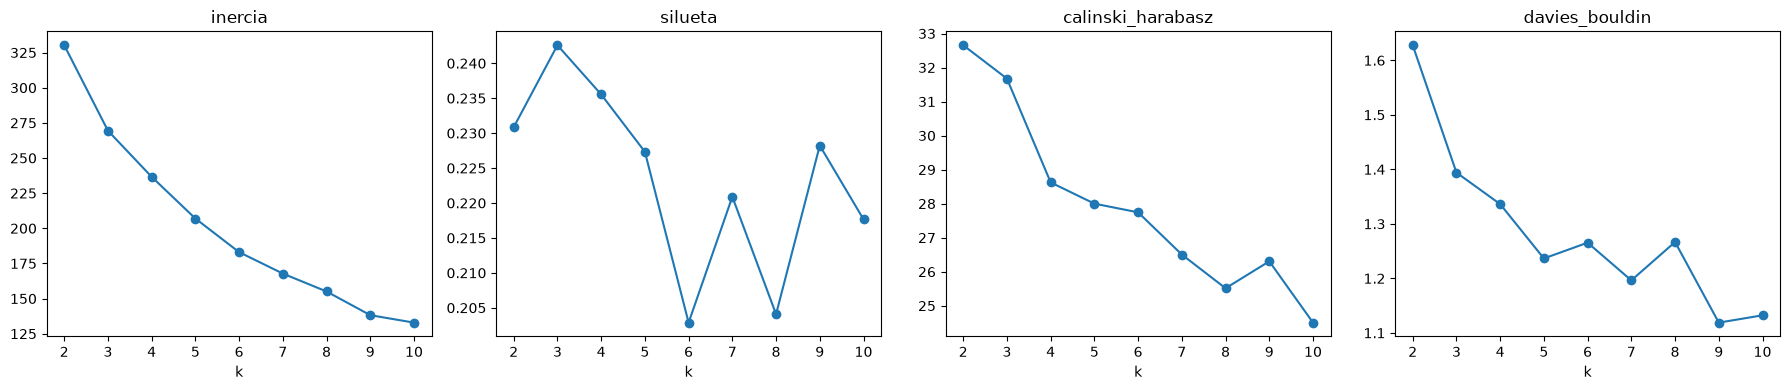


K = 3
Silueta: 0.243
Calinski-Harabasz: 31.675
Davies-Bouldin: 1.394
         muertes_por_ano  pct_fin_semana  pct_Noche  pct_ATROPELLO  \
cluster                                                              
0                  2.383           0.205      0.409          0.436   
1                  2.567           0.315      0.199          0.358   
2                  5.532           0.309      0.316          0.500   

         pct_Madrugada  pct_Mañana  pct_Tarde  pct_CHOQUE  pct_OTRO  \
cluster                                                               
0                0.158       0.224      0.210       0.465     0.007   
1                0.202       0.310      0.289       0.523     0.017   
2                0.181       0.249      0.254       0.417     0.014   

         pct_VOLCAMIENTO  n_zonas  muertes_totales  
cluster                                             
0                  0.092       22              367  
1                  0.102       35              629  
2          

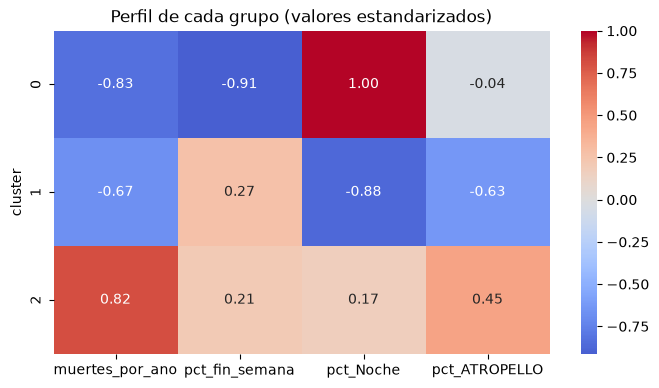

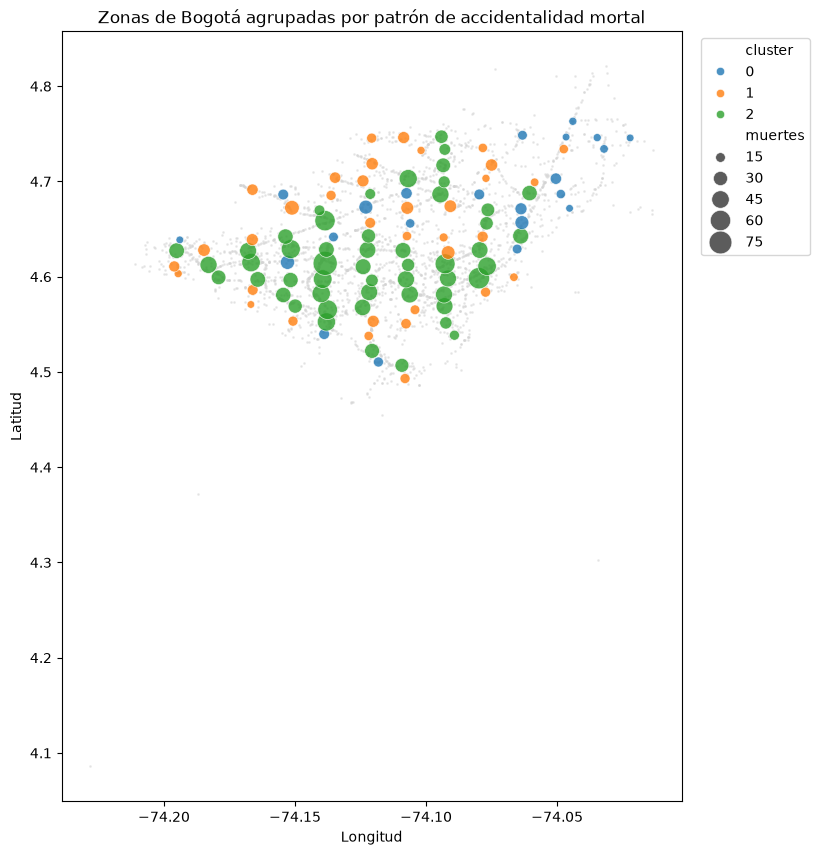

In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

# =========================================================
# 1. DEFINIR ZONAS (cuadrícula espacial)
# =========================================================
TAM_CELDA = 0.015      # grados (~1.7 km)
MIN_MUERTES = 10       # mínimo de muertes para que la zona sea confiable

df["ZONA"] = (np.floor(df["LATITUD"] / TAM_CELDA).astype(int).astype(str) + "_" +
              np.floor(df["LONGITUD"] / TAM_CELDA).astype(int).astype(str))

# Agrupar clases poco frecuentes
df["CLASE_AGR"] = df["CLASE_ACC"].replace({"CAIDA DE OCUPANTE": "OTRO"})
n_anos = df["ANO_OCURRENCIA_ACC"].nunique()

# =========================================================
# 2. PERFIL POR ZONA
# =========================================================
zonas = df.groupby("ZONA").agg(
    muertes=("HORA", "size"),
    lat=("LATITUD", "mean"),
    lon=("LONGITUD", "mean"),
    localidad=("LOCALIDAD", lambda s: s.mode().iat[0]),
    pct_fin_semana=("FIN_SEMANA", "mean"),
)
franja = pd.crosstab(df["ZONA"], df["FRANJA"], normalize="index").add_prefix("pct_")
clase  = pd.crosstab(df["ZONA"], df["CLASE_AGR"], normalize="index").add_prefix("pct_")
zonas = zonas.join(franja).join(clase)
zonas["muertes_por_ano"] = zonas["muertes"] / n_anos

zonas = zonas[zonas["muertes"] >= MIN_MUERTES].copy()
print("Zonas a agrupar:", len(zonas), "| muertes cubiertas:", zonas["muertes"].sum())

# =========================================================
# 3. VARIABLES DEL MODELO Y ESCALADO
# =========================================================
features = ["muertes_por_ano", "pct_fin_semana", "pct_Noche", "pct_ATROPELLO"]

X = zonas[features].copy()
X["muertes_por_ano"] = np.log1p(X["muertes_por_ano"])   # reduce la asimetría
X_scaled = StandardScaler().fit_transform(X)

# =========================================================
# 4. ELEGIR K: CODO + MÉTRICAS
# =========================================================
resultados = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X_scaled)
    resultados.append({
        "k": k,
        "inercia": km.inertia_,
        "silueta": silhouette_score(X_scaled, km.labels_),
        "calinski_harabasz": calinski_harabasz_score(X_scaled, km.labels_),
        "davies_bouldin": davies_bouldin_score(X_scaled, km.labels_),
    })
res = pd.DataFrame(resultados).set_index("k")
print(res.round(3))

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, res.columns):
    ax.plot(res.index, res[col], marker="o")
    ax.set_title(col); ax.set_xlabel("k")
plt.tight_layout(); plt.show()

# =========================================================
# 5. MODELO FINAL
# =========================================================
K = 3   # ajústalo según las gráficas anteriores
kmeans = KMeans(n_clusters=K, n_init=20, random_state=42).fit(X_scaled)
zonas["cluster"] = kmeans.labels_

print(f"\nK = {K}")
print("Silueta:", round(silhouette_score(X_scaled, zonas["cluster"]), 3))
print("Calinski-Harabasz:", round(calinski_harabasz_score(X_scaled, zonas["cluster"]), 3))
print("Davies-Bouldin:", round(davies_bouldin_score(X_scaled, zonas["cluster"]), 3))

# =========================================================
# 6. CARACTERIZACIÓN DE LOS GRUPOS
# =========================================================
cols_perfil = features + [c for c in zonas.columns if c.startswith("pct_") and c not in features]
perfil = zonas.groupby("cluster")[cols_perfil].mean().round(3)
perfil["n_zonas"] = zonas["cluster"].value_counts().sort_index()
perfil["muertes_totales"] = zonas.groupby("cluster")["muertes"].sum()
print(perfil)

# Localidades más frecuentes en cada grupo
print(zonas.groupby("cluster")["localidad"].agg(lambda s: s.value_counts().head(5).to_dict()))

# Perfil estandarizado (para ver qué distingue a cada grupo)
perfil_z = pd.DataFrame(X_scaled, columns=features, index=zonas.index).groupby(zonas["cluster"]).mean()
plt.figure(figsize=(8, 3 + K * 0.4))
sns.heatmap(perfil_z, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Perfil de cada grupo (valores estandarizados)"); plt.show()

# =========================================================
# 7. MAPA DE LAS ZONAS
# =========================================================
plt.figure(figsize=(8, 10))
plt.scatter(df["LONGITUD"], df["LATITUD"], s=1, c="lightgrey", alpha=0.4)
sns.scatterplot(data=zonas, x="lon", y="lat", hue="cluster", size="muertes",
                sizes=(30, 300), palette="tab10", alpha=0.8)
plt.title("Zonas de Bogotá agrupadas por patrón de accidentalidad mortal")
plt.xlabel("Longitud"); plt.ylabel("Latitud")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.show()

### Clustering Jerárquico

  metodo  k  cofenetica  silueta                 tamanos
    ward  2       0.519    0.250                [30, 78]
    ward  3       0.519    0.170            [30, 43, 35]
    ward  4       0.519    0.198        [10, 20, 43, 35]
    ward  5       0.519    0.181    [10, 20, 43, 15, 20]
    ward  6       0.519    0.198 [10, 9, 11, 43, 15, 20]
complete  2       0.546    0.398                [3, 105]
complete  3       0.546    0.166             [3, 68, 37]
complete  4       0.546    0.154          [3, 68, 6, 31]
complete  5       0.546    0.104      [3, 68, 6, 11, 20]
complete  6       0.546    0.148  [3, 47, 21, 6, 11, 20]
 average  2       0.745    0.457                [107, 1]
 average  3       0.745    0.358             [2, 105, 1]
 average  4       0.745    0.252          [2, 5, 100, 1]
 average  5       0.745    0.126        [2, 5, 3, 97, 1]
 average  6       0.745    0.148    [2, 5, 3, 11, 86, 1]
  single  2       0.706    0.457                [107, 1]
  single  3       0.706    0.35

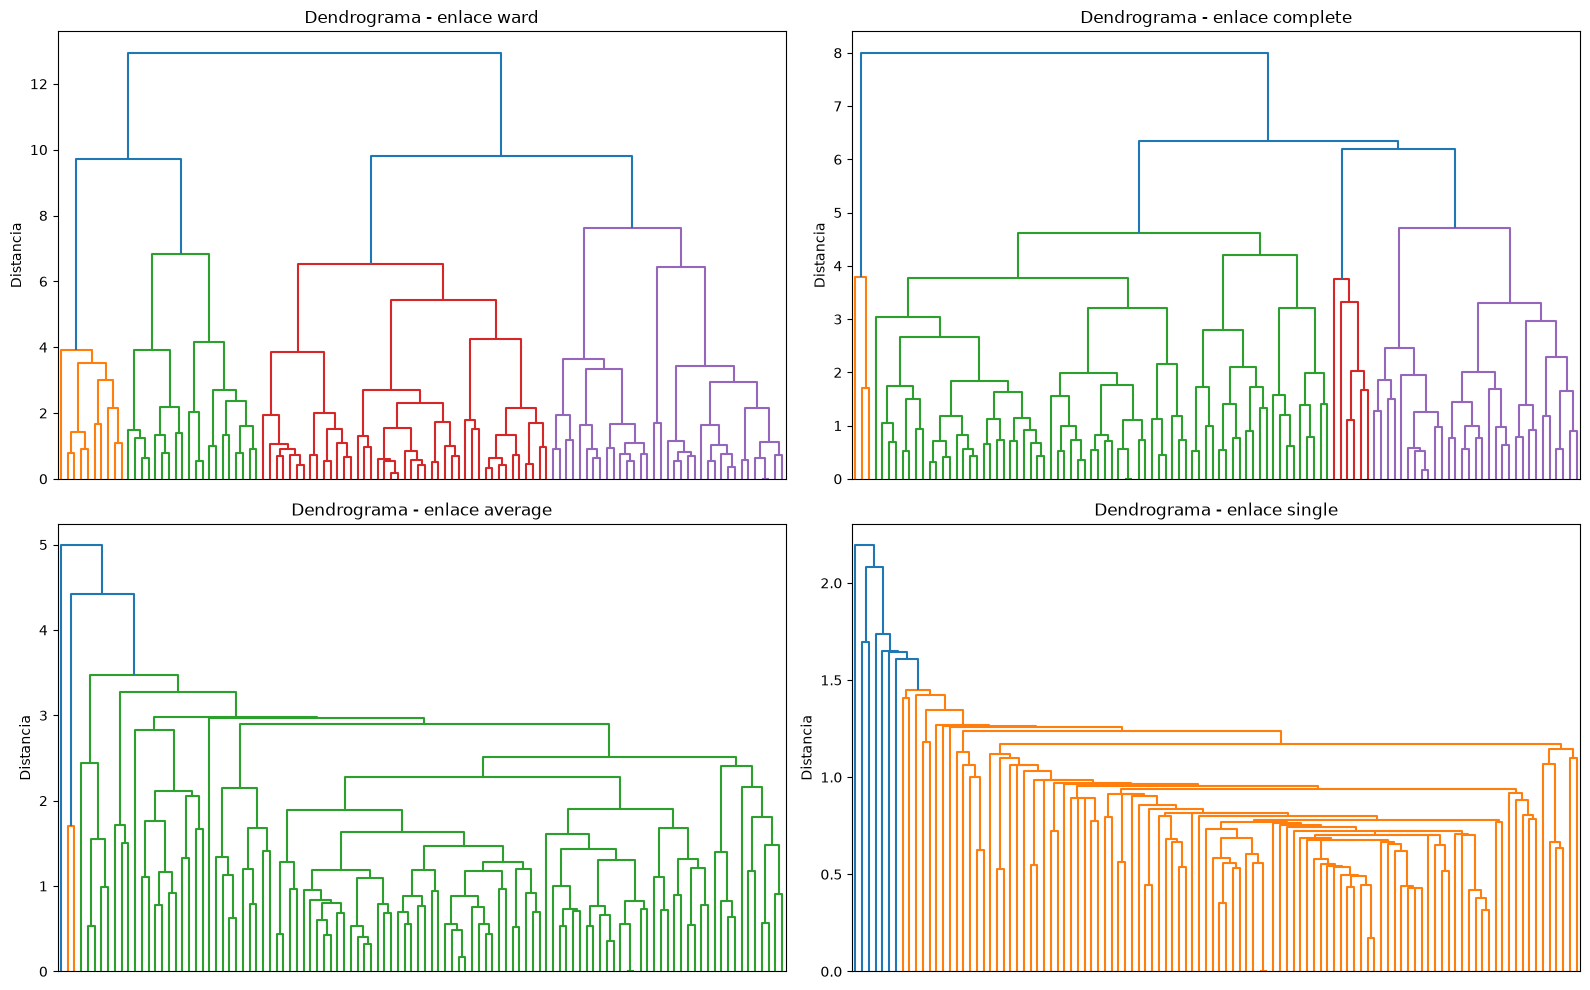

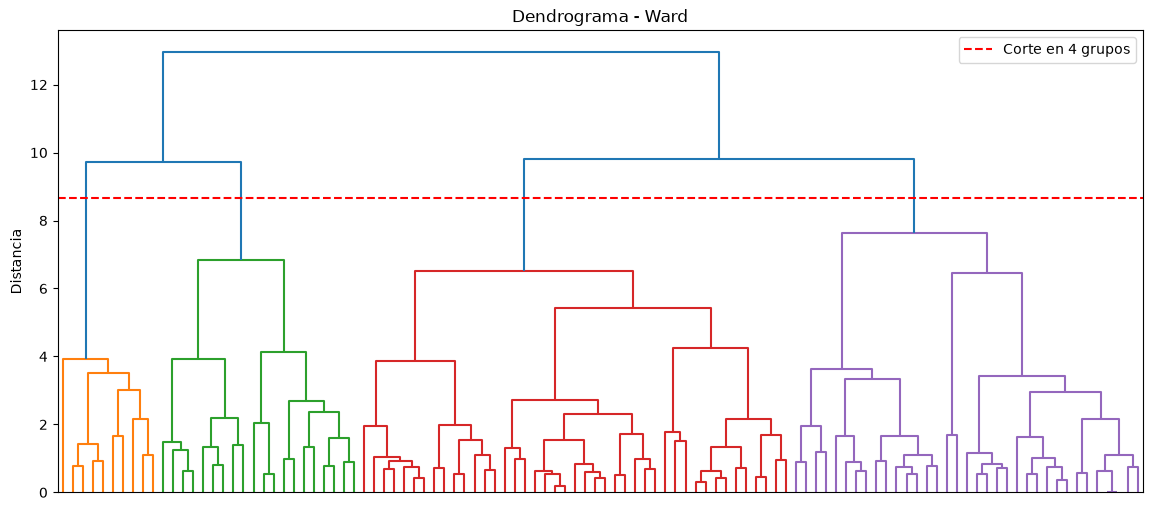

    silueta  calinski_harabasz  davies_bouldin
k                                             
2     0.250             25.521           1.762
3     0.170             23.093           1.742
4     0.198             24.571           1.514
5     0.181             23.968           1.386
6     0.198             23.565           1.279
7     0.183             23.758           1.310
8     0.202             24.677           1.201
9     0.218             24.840           1.134
10    0.213             24.060           1.092


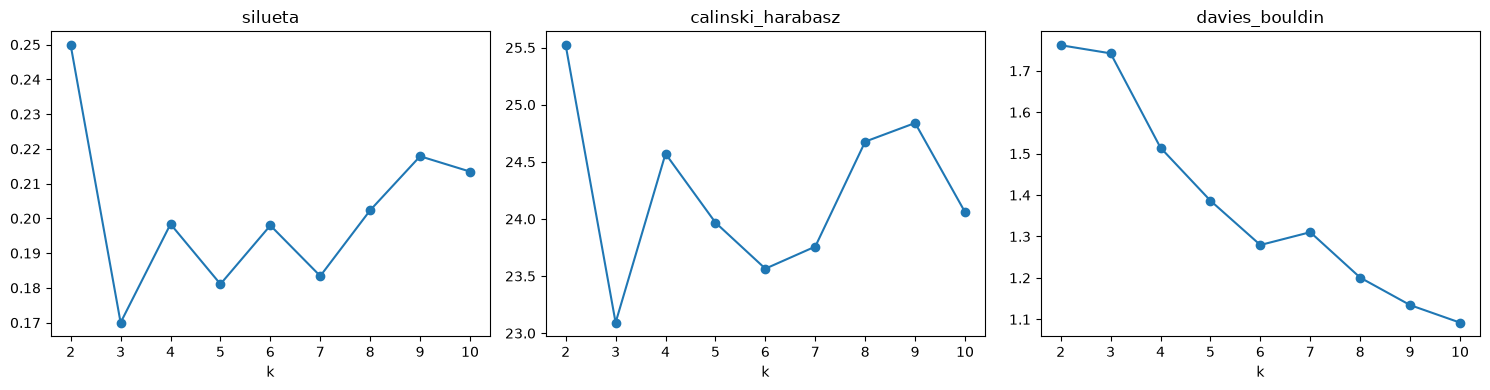


Jerárquico Ward, K = 4
Silueta: 0.198
Calinski-Harabasz: 24.571
Davies-Bouldin: 1.514
            muertes_por_ano  pct_fin_semana  pct_Noche  pct_ATROPELLO  \
cluster_hc                                                              
0                     2.543           0.247      0.519          0.419   
1                     1.971           0.207      0.239          0.329   
2                     5.930           0.299      0.312          0.453   
3                     2.988           0.338      0.247          0.497   

            pct_Madrugada  pct_Mañana  pct_Tarde  pct_CHOQUE  pct_OTRO  \
cluster_hc                                                               
0                   0.126       0.201      0.154       0.460     0.015   
1                   0.184       0.300      0.277       0.563     0.007   
2                   0.185       0.247      0.256       0.456     0.015   
3                   0.196       0.283      0.274       0.410     0.014   

            pct_VOLCAMIENTO  

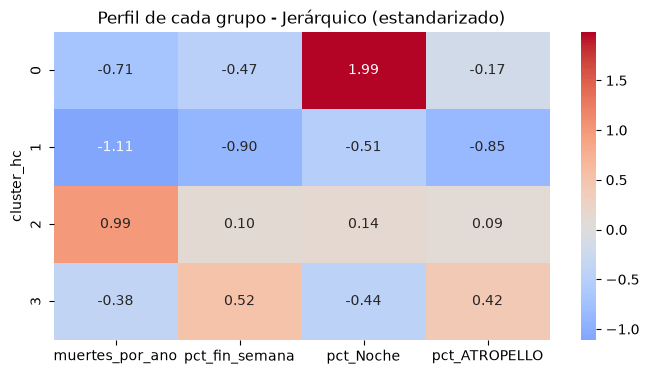

Tabla cruzada K-means (filas) vs Jerárquico (columnas):
cluster_hc   0   1   2   3
cluster                   
0           10   8   1   3
1            0  12   5  18
2            0   0  37  14
Adjusted Rand Index: 0.336


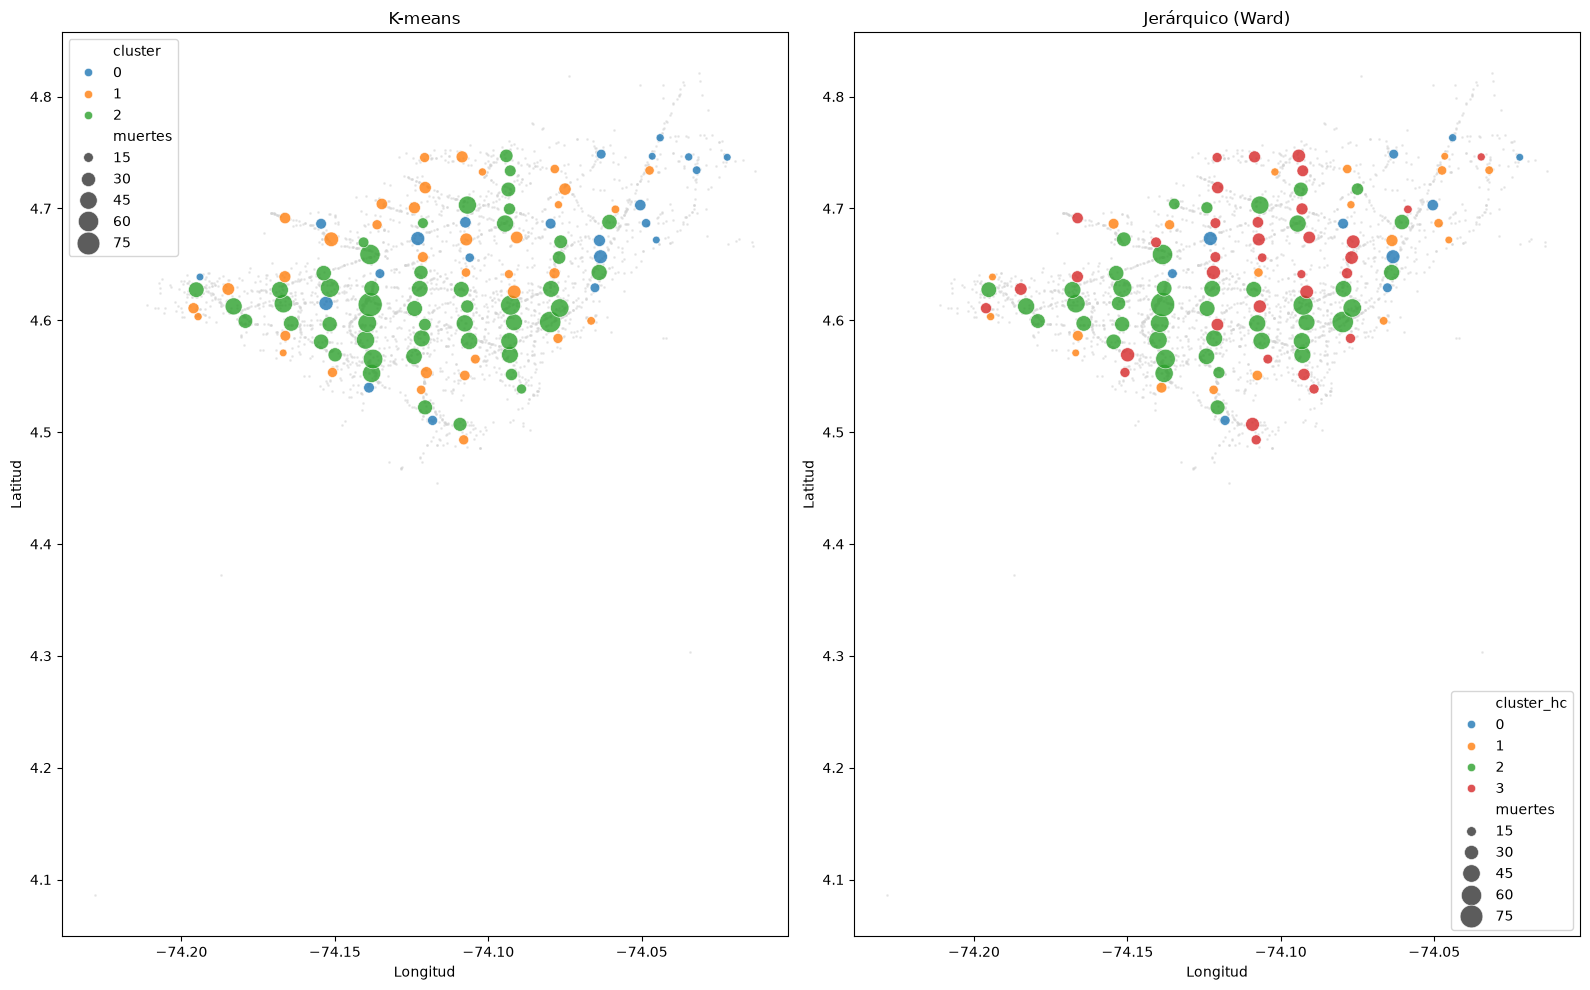

In [16]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)

# =========================================================
# 1. COMPARAR MÉTODOS DE ENLACE (linkage)
# =========================================================
metodos = ["ward", "complete", "average", "single"]
distancias = pdist(X_scaled)        # distancias euclidianas entre zonas

comparacion = []
for m in metodos:
    Z = linkage(X_scaled, method=m)
    coph, _ = cophenet(Z, distancias)        # qué tan bien el dendrograma respeta las distancias reales
    for k in range(2, 7):
        etiquetas = fcluster(Z, k, criterion="maxclust")
        tamanos = np.bincount(etiquetas)[1:].tolist()
        comparacion.append({
            "metodo": m, "k": k, "cofenetica": round(coph, 3),
            "silueta": round(silhouette_score(X_scaled, etiquetas), 3),
            "tamanos": tamanos,
        })
comparacion = pd.DataFrame(comparacion)
print(comparacion.to_string(index=False))

# =========================================================
# 2. DENDROGRAMAS
# =========================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, m in zip(axes.ravel(), metodos):
    dendrogram(linkage(X_scaled, method=m), ax=ax, no_labels=True, color_threshold=None)
    ax.set_title(f"Dendrograma - enlace {m}")
    ax.set_ylabel("Distancia")
plt.tight_layout(); plt.show()

# =========================================================
# 3. MODELO FINAL: WARD
# =========================================================
Z_ward = linkage(X_scaled, method="ward")

# Dendrograma con línea de corte
K_HC = 4
corte = (Z_ward[-K_HC, 2] + Z_ward[-K_HC + 1, 2]) / 2
plt.figure(figsize=(14, 6))
dendrogram(Z_ward, no_labels=True, color_threshold=corte)
plt.axhline(corte, color="red", linestyle="--", label=f"Corte en {K_HC} grupos")
plt.title("Dendrograma - Ward"); plt.ylabel("Distancia"); plt.legend(); plt.show()

# Métricas para varios k con Ward
res_hc = []
for k in range(2, 11):
    et = fcluster(Z_ward, k, criterion="maxclust")
    res_hc.append({
        "k": k,
        "silueta": silhouette_score(X_scaled, et),
        "calinski_harabasz": calinski_harabasz_score(X_scaled, et),
        "davies_bouldin": davies_bouldin_score(X_scaled, et),
    })
res_hc = pd.DataFrame(res_hc).set_index("k")
print(res_hc.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, res_hc.columns):
    ax.plot(res_hc.index, res_hc[col], marker="o"); ax.set_title(col); ax.set_xlabel("k")
plt.tight_layout(); plt.show()

zonas["cluster_hc"] = fcluster(Z_ward, K_HC, criterion="maxclust") - 1   # etiquetas 0,1,2

print(f"\nJerárquico Ward, K = {K_HC}")
print("Silueta:", round(silhouette_score(X_scaled, zonas["cluster_hc"]), 3))
print("Calinski-Harabasz:", round(calinski_harabasz_score(X_scaled, zonas["cluster_hc"]), 3))
print("Davies-Bouldin:", round(davies_bouldin_score(X_scaled, zonas["cluster_hc"]), 3))

# =========================================================
# 4. CARACTERIZACIÓN
# =========================================================
perfil_hc = zonas.groupby("cluster_hc")[cols_perfil].mean().round(3)
perfil_hc["n_zonas"] = zonas["cluster_hc"].value_counts().sort_index()
perfil_hc["muertes_totales"] = zonas.groupby("cluster_hc")["muertes"].sum()
print(perfil_hc)
print(zonas.groupby("cluster_hc")["localidad"].agg(lambda s: s.value_counts().head(5).to_dict()))

perfil_z_hc = pd.DataFrame(X_scaled, columns=features, index=zonas.index).groupby(zonas["cluster_hc"]).mean()
plt.figure(figsize=(8, 4))
sns.heatmap(perfil_z_hc, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Perfil de cada grupo - Jerárquico (estandarizado)"); plt.show()

# =========================================================
# 5. COMPARACIÓN CON K-MEANS
# =========================================================
print("Tabla cruzada K-means (filas) vs Jerárquico (columnas):")
print(pd.crosstab(zonas["cluster"], zonas["cluster_hc"]))
print("Adjusted Rand Index:", round(adjusted_rand_score(zonas["cluster"], zonas["cluster_hc"]), 3))

# Mapas lado a lado
fig, axes = plt.subplots(1, 2, figsize=(16, 10))
for ax, col, titulo in zip(axes, ["cluster", "cluster_hc"], ["K-means", "Jerárquico (Ward)"]):
    ax.scatter(df["LONGITUD"], df["LATITUD"], s=1, c="lightgrey", alpha=0.4)
    sns.scatterplot(data=zonas, x="lon", y="lat", hue=col, size="muertes",
                    sizes=(30, 300), palette="tab10", alpha=0.8, ax=ax)
    ax.set_title(titulo); ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud")
plt.tight_layout(); plt.show()

## Modelo nuevo: PCA + K-Means

Varianza acumulada: [0.219 0.418 0.576 0.695 0.799 0.892 0.978 0.991 1.    1.    1.   ]


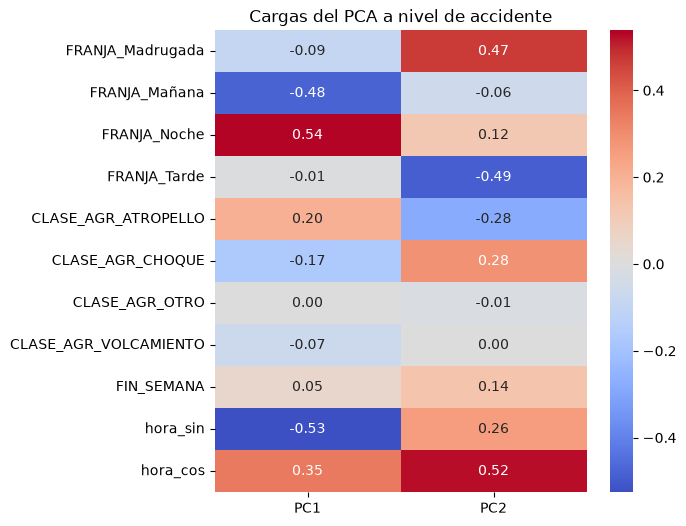

 k                       tamanos  silueta  calinski  davies
 2                      [66, 42]    0.273    40.524   1.398
 3                  [21, 43, 44]    0.301    42.811   1.155
 4              [11, 42, 45, 10]    0.335    45.710   0.998
 5          [31, 10, 11, 23, 33]    0.292    43.641   1.065
 6       [13, 32, 10, 9, 20, 24]    0.287    43.789   1.048
 7    [17, 21, 34, 8, 13, 4, 11]    0.294    43.972   1.004
 8 [9, 12, 26, 3, 11, 7, 23, 17]    0.296    45.547   0.967


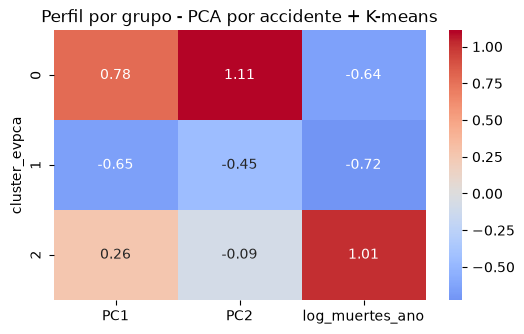

               muertes_por_ano  pct_fin_semana  pct_Noche  pct_ATROPELLO  \
cluster_evpca                                                              
0                        2.626           0.290      0.407          0.393   
1                        2.488           0.278      0.223          0.421   
2                        5.961           0.301      0.316          0.483   

               pct_Madrugada  pct_Mañana  pct_Tarde  pct_CHOQUE  pct_OTRO  \
cluster_evpca                                                               
0                      0.232       0.187      0.174       0.508     0.009   
1                      0.158       0.323      0.296       0.473     0.013   
2                      0.184       0.244      0.257       0.427     0.016   

               pct_VOLCAMIENTO  n_zonas  
cluster_evpca                            
0                        0.090       21  
1                        0.093       43  
2                        0.074       44  


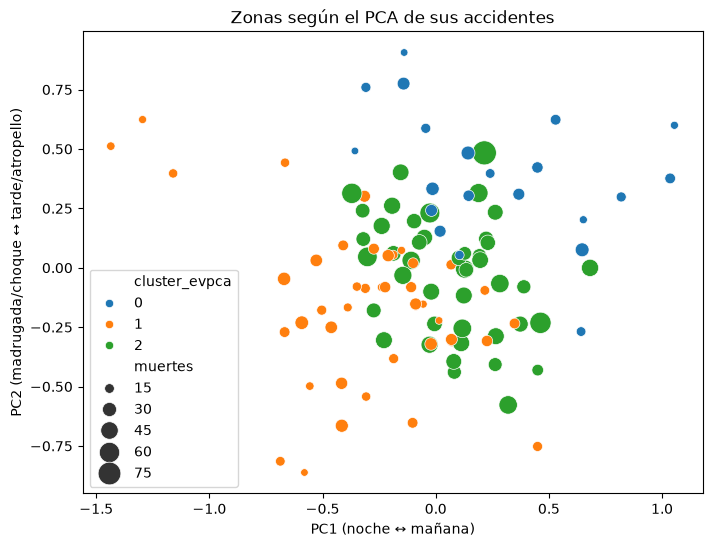

In [19]:
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import squareform


# =========================================================
# PCA A NIVEL DE ACCIDENTE -> CARACTERÍSTICAS POR ZONA
# =========================================================
# 1. Accidentes de las zonas seleccionadas
ev = df[df["ZONA"].isin(zonas.index)].copy()

# 2. Variables originales en forma numérica
E = pd.get_dummies(ev[["FRANJA", "CLASE_AGR"]].astype(str)).astype(float)
E["FIN_SEMANA"] = ev["FIN_SEMANA"]
E["hora_sin"] = np.sin(2 * np.pi * ev["HORA"] / 24)     # hora cíclica
E["hora_cos"] = np.cos(2 * np.pi * ev["HORA"] / 24)
E_scaled = StandardScaler().fit_transform(E)

# 3. PCA sobre los accidentes
pca_ev_full = PCA().fit(E_scaled)
print("Varianza acumulada:", np.cumsum(pca_ev_full.explained_variance_ratio_).round(3))

N_COMP_EV = 2
pca_ev = PCA(n_components=N_COMP_EV, random_state=42).fit(E_scaled)
cargas_ev = pd.DataFrame(pca_ev.components_.T, index=E.columns,
                         columns=[f"PC{i+1}" for i in range(N_COMP_EV)])
plt.figure(figsize=(6, 6))
sns.heatmap(cargas_ev, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Cargas del PCA a nivel de accidente"); plt.show()

# 4. Promediar los componentes por zona y agregar la intensidad
scores = pd.DataFrame(pca_ev.transform(E_scaled), index=ev.index, columns=cargas_ev.columns)
feat_zona = scores.groupby(ev["ZONA"]).mean().loc[zonas.index]
feat_zona["log_muertes_ano"] = np.log1p(zonas["muertes_por_ano"])

X_evpca = StandardScaler().fit_transform(feat_zona)

# 5. Elegir k
res_evpca = []
for k in range(2, 9):
    lab = KMeans(n_clusters=k, n_init=20, random_state=42).fit_predict(X_evpca)
    res_evpca.append({"k": k, "tamanos": np.bincount(lab).tolist(),
                      "silueta": round(silhouette_score(X_evpca, lab), 3),
                      "calinski": round(calinski_harabasz_score(X_evpca, lab), 3),
                      "davies": round(davies_bouldin_score(X_evpca, lab), 3)})
print(pd.DataFrame(res_evpca).to_string(index=False))

# 6. Modelo final
K_EVPCA = 3
zonas["cluster_evpca"] = KMeans(n_clusters=K_EVPCA, n_init=20, random_state=42).fit_predict(X_evpca)
# Alternativa jerárquica sobre las mismas características:
# zonas["cluster_evpca_hc"] = fcluster(linkage(X_evpca, "ward"), K_EVPCA, "maxclust") - 1

# 7. Perfil (en componentes y en porcentajes reales)
perfil_ev = pd.DataFrame(X_evpca, columns=feat_zona.columns, index=zonas.index) \
              .groupby(zonas["cluster_evpca"]).mean()
plt.figure(figsize=(6, 3.5))
sns.heatmap(perfil_ev, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Perfil por grupo - PCA por accidente + K-means"); plt.show()

print(zonas.groupby("cluster_evpca")[cols_perfil].mean().round(3)
        .assign(n_zonas=zonas["cluster_evpca"].value_counts().sort_index()))

# 8. Grupos en el plano PC1-PC2 de las zonas
plt.figure(figsize=(8, 6))
sns.scatterplot(x=feat_zona["PC1"], y=feat_zona["PC2"], hue=zonas["cluster_evpca"],
                size=zonas["muertes"], sizes=(30, 300), palette="tab10")
plt.xlabel("PC1 (noche ↔ mañana)"); plt.ylabel("PC2 (madrugada/choque ↔ tarde/atropello)")
plt.title("Zonas según el PCA de sus accidentes"); plt.show()